# Лабораторная работа № 1
## Решение варианта № 5

**Дисциплина:** «Методы анализа больших данных»  
**Профиль:** «Информатика и английский язык»  
**Среда:** Google Colab, Python 3.10+

### Постановка задачи

Для учащихся с `race/ethnicity == "group C"` сравнить результаты по письму (`writing score`) в двух группах:

- подготовительный курс пройден — `completed`;
- подготовительный курс не пройден — `none`.

Рассмотреть гипотезу, согласно которой завершение подготовительного курса в группе С связанно с более высокими баллами по письму.

Перед анализом проверить качество данных, обработать пропуски и потенциальные выбросы методом IQR. Затем сравнить средние значения `writing score` и проверить гипотезу односторонним Welch t-test при $\alpha=0.05$.

**Дополнительно:** повторить основные расчёты для очищенных данных в **BigQuery** и сопоставить их с результатами `pandas`.

> Важно: обнаруженная статистическая связь не доказывает причинное влияние подготовительного курса.

## Блок 1. Импорт библиотек и прямая загрузка датасета

Основной URL берётся строго из условия лабораторной работы. Если он недоступен по сетевой или HTTP-причине, код автоматически обращается к резервному публичному URL на тот же `StudentsPerformance.csv`.

Ручная загрузка файла в Colab не используется.


In [13]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

PRIMARY_URL = "https://raw.githubusercontent.com/sriharikadali/Students-Performance-in-Exams/master/StudentsPerformance.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv"


def load_students_performance(primary_url: str, fallback_url: str):
    """
    Загружает CSV непосредственно по HTTPS.
    Сначала используется URL из задания, затем резервный URL.
    """
    errors = []

    for url in (primary_url, fallback_url):
        try:
            with urllib.request.urlopen(url, timeout=30) as response:
                raw_bytes = response.read()

            dataframe = pd.read_csv(io.BytesIO(raw_bytes))

            required_columns = {
                "gender",
                "race/ethnicity",
                "parental level of education",
                "lunch",
                "test preparation course",
                "math score",
                "reading score",
                "writing score",
            }

            missing_columns = required_columns - set(dataframe.columns)
            if missing_columns:
                raise ValueError(
                    f"Отсутствуют обязательные столбцы: {sorted(missing_columns)}"
                )

            return dataframe, url

        except Exception as exc:
            errors.append(
                f"{url} -> {type(exc).__name__}: {exc}"
            )

    raise RuntimeError(
        "Не удалось загрузить датасет.\n" + "\n".join(errors)
    )


df_raw, USED_URL = load_students_performance(PRIMARY_URL, FALLBACK_URL)

print("Dataset loaded successfully / Датасет успешно загружен")
print("Used URL / Использованный URL:")
print(USED_URL)
print("Shape / Размер:", df_raw.shape)

display(df_raw.head())


Dataset loaded successfully / Датасет успешно загружен
Used URL / Использованный URL:
https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv
Shape / Размер: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Короткое пояснение результата

Загружен датасет из **1000 строк и 8 столбцов**. Использован резервный URL, потому что основной адрес во время запуска оказался недоступен. Структура файла соответствует условию лабораторной работы.

## Блок 2. Первичная проверка и контроль качества

Проверяются:

- структура таблицы;
- типы данных;
- пропуски $NaN$;
- полные дубликаты;
- диапазон баллов 0–100;
- значения категориальных полей.

Доля пропусков:

$$
r_{miss}=\frac{N_{miss}}{N}.
$$


In [17]:
score_cols = ["reading score", "writing score"] #Исключаем math_scores, как незначащие для нашего варианта

categorical_cols = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]

print("Rows, columns / Строки, столбцы:", df_raw.shape)

print("\n--- INFO ---")
df_raw.info()

print("\n--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---")
display(df_raw.head())

missing_report = df_raw.isna().sum().to_frame("missing_count")
missing_report["missing_percent"] = (
    missing_report["missing_count"] / len(df_raw) * 100
)

print("\n--- MISSING VALUES / ПРОПУСКИ ---")
display(missing_report)

duplicate_count = int(df_raw.duplicated().sum())
print("Exact duplicates / Полные дубликаты:", duplicate_count)

print("\n--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---")
display(df_raw[score_cols].describe().T)

range_check = pd.DataFrame({
    "below_0": (df_raw[score_cols] < 0).sum(),
    "above_100": (df_raw[score_cols] > 100).sum(),
})

print("\n--- RANGE CHECK 0..100 / ПРОВЕРКА ДИАПАЗОНА ---")
display(range_check)

for col in categorical_cols:
    print(f"\nColumn / Столбец: {col}")
    display(df_raw[col].value_counts(dropna=False).to_frame("count"))


Rows, columns / Строки, столбцы: (1000, 8)

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- MISSING VALUES / ПРОПУСКИ ---


,missing_count,missing_percent
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


Exact duplicates / Полные дубликаты: 0

--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---


...

,count
parental level of education,
some college,226
associate's degree,222
high school,196
some high school,179
bachelor's degree,118
master's degree,59



Column / Столбец: lunch


,count
lunch,
standard,645
free/reduced,355



Column / Столбец: test preparation course


,count
test preparation course,
none,642
completed,358


### Короткое пояснение результата

В исходных данных **нет пропусков и полных дубликатов**. Все три экзаменационных балла находятся в допустимом диапазоне **0–100**. Значит, дополнительного исправления пропусков для этого запуска не требуется, но код обработки оставлен как часть воспроизводимого конвейера.

### Обработка пропусков варианта № 5

Даже если исходный файл не содержит `NaN`, алгоритм обработки должен быть реализован полностью:

- числовые признаки → медиана;
- категориальные признаки → мода.

Исходный `df_raw` не изменяется.


In [18]:
df = df_raw.copy()

# Удаление полных дублей, если они есть.
n_before = len(df)
df = df.drop_duplicates().copy()
n_after = len(df)

print(
    "Removed exact duplicates / Удалено полных дублей:",
    n_before - n_after
)

# Медианная импутация числовых полей.
for col in score_cols:
    missing_before = int(df[col].isna().sum())
    median_value = df[col].median()

    df[col] = df[col].fillna(median_value)

    print(
        f"{col}: NaN before={missing_before}; "
        f"median={median_value:.2f}"
    )

# Импутация модой категориальных полей.
for col in categorical_cols:
    missing_before = int(df[col].isna().sum())

    if missing_before > 0:
        mode_series = df[col].mode(dropna=True)

        if mode_series.empty:
            raise ValueError(
                f"Невозможно определить моду для столбца {col}"
            )

        mode_value = mode_series.iloc[0]
        df[col] = df[col].fillna(mode_value)
    else:
        mode_value = "not required / не требуется"

    print(
        f"{col}: NaN before={missing_before}; "
        f"mode={mode_value}"
    )

print("\nNaN after imputation / Пропуски после импутации:")
display(df.isna().sum().to_frame("missing_count"))


Removed exact duplicates / Удалено полных дублей: 0
reading score: NaN before=0; median=70.00
writing score: NaN before=0; median=69.00
gender: NaN before=0; mode=not required / не требуется
race/ethnicity: NaN before=0; mode=not required / не требуется
parental level of education: NaN before=0; mode=not required / не требуется
lunch: NaN before=0; mode=not required / не требуется
test preparation course: NaN before=0; mode=not required / не требуется

NaN after imputation / Пропуски после импутации:


,missing_count
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


### Короткое пояснение результата

Импутация фактически не изменила таблицу: во всех столбцах было `0` пропусков. Медианы числовых признаков рассчитаны корректно, но подстановка значений не потребовалась.

## Блок 3. Поиск и обработка выбросов методом IQR

Для каждого экзаменационного показателя:

$$
IQR=Q_3-Q_1,
$$

$$
L=Q_1-1.5\cdot IQR,
$$

$$
U=Q_3+1.5\cdot IQR.
$$

Строка исключается в учебном решении, если хотя бы один из трёх баллов находится вне своего IQR-интервала.

В реальном образовательном исследовании такие наблюдения сначала должны проходить предметную проверку: низкий или высокий балл может быть редким, но корректным результатом.


In [19]:
iqr_bounds = {}
outlier_mask = pd.Series(False, index=df.index)

for col in score_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_bounds[col] = {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower": lower,
        "upper": upper,
    }

    current_outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    )

    outlier_mask = outlier_mask | current_outliers

bounds_df = pd.DataFrame(iqr_bounds).T

bounds_df["outlier_count"] = [
    int(
        (
            (df[col] < bounds_df.loc[col, "lower"]) |
            (df[col] > bounds_df.loc[col, "upper"])
        ).sum()
    )
    for col in score_cols
]

display(bounds_df.round(3))

print(
    "Rows with >=1 IQR outlier / "
    "Строк с хотя бы одним IQR-выбросом:",
    int(outlier_mask.sum())
)

df_clean = df.loc[~outlier_mask].copy()

print("Rows before / Строк до очистки:", len(df))
print("Rows after / Строк после очистки:", len(df_clean))
print("Removed / Удалено:", len(df) - len(df_clean))

# Контроль качества после очистки.
assert df_clean[score_cols].notna().all().all()
assert (
    ((df_clean[score_cols] >= 0) &
     (df_clean[score_cols] <= 100))
    .all()
    .all()
)

display(df_clean.head())


,Q1,Q3,IQR,lower,upper,outlier_count
reading score,59.00,79.0,20.00,29.000,109.000,6
writing score,57.75,79.0,21.25,25.875,110.875,5


Rows with >=1 IQR outlier / Строк с хотя бы одним IQR-выбросом: 6
Rows before / Строк до очистки: 1000
Rows after / Строк после очистки: 994
Removed / Удалено: 6


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Короткое пояснение результата

Метод IQR отметил **6 строк** как содержащие хотя бы один потенциальный выброс. После учебной очистки осталось **994 строки**.

> Потенциальный выброс не обязательно является ошибкой. В реальном образовательном исследовании такие наблюдения сначала нужно проверить содержательно.

### Дополнительная демонстрация Min-Max нормализации

Исходные баллы сохраняются, а нормализованные значения создаются в новых столбцах:

$$
x_{norm}=\frac{x-x_{min}}{x_{max}-x_{min}}.
$$


In [20]:
df_normalized = df_clean.copy()

for col in score_cols:
    x_min = df_clean[col].min()
    x_max = df_clean[col].max()

    if x_max == x_min:
        df_normalized[col + "_norm"] = 0.0
    else:
        df_normalized[col + "_norm"] = (
            (df_clean[col] - x_min) /
            (x_max - x_min)
        )

norm_cols = [col + "_norm" for col in score_cols]
display(df_normalized[norm_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
reading score_norm,994.0,0.569629,0.200078,0.0,0.436620,0.577465,0.714789,1.0
writing score_norm,994.0,0.566412,0.202113,0.0,0.424658,0.575342,0.712329,1.0


### Короткое пояснение результата

После Min-Max нормализации значения каждого экзаменационного показателя находятся в диапазоне **0–1**. В варианте № 25 нормализованные столбцы используются только как демонстрация и не заменяют исходные баллы при проверке гипотезы.

### Фильтрация варианта № 5

Оставляем учащихся с `group C` race/ethnicity. Затем сравниваем подгруппы `completed` и `none`.


In [21]:
df_v5 = df_clean.loc[
    df_clean["race/ethnicity"].eq("group C")
].copy()

group_counts = (
    df_v5["test preparation course"]
    .value_counts()
    .rename_axis("test_preparation")
    .to_frame("n")
)

print(
    "Variant 5 sample / Выборка варианта 55:",
    df_v5.shape
)

display(group_counts)

group_stats = (
    df_v5
    .groupby("test preparation course")[score_cols]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(group_stats.round(2))


Variant 5 sample / Выборка варианта 55: (317, 8)


,n
test_preparation,
none,200
completed,117


reading score                               writing score                              
                                count   mean median    std min  max         count   mean median    std min  max
test preparation course                                                                                        
completed                         117  73.66   75.0  14.00  37  100           117  74.45   77.0  13.56  40  100
none                              200  66.90   67.0  12.64  29   95           200  64.44   65.0  13.75  30   95

### Короткое пояснение результата

После фильтра `race/ethnicity == "group C"` осталось **317 учащихся**:

- `completed` — **117**;
- `none` — **200**.

Средний `writing score` составляет **74.45** у прошедших подготовительный курс и **64,44** у не проходивших. Наблюдаемая разница средних — примерно **10,01 балла**. Далее проверим, является ли это различие статистически значимым.

## Блок 4. Визуализация

Строятся три обязательных графика:

1. Boxplot.
2. Histplot.
3. Correlation Heatmap.

Подписи выполняются на английском и русском языках.


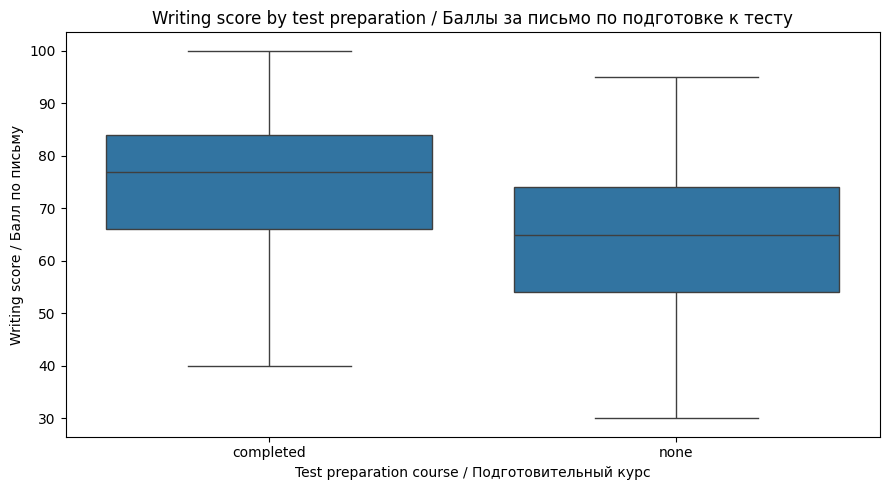

In [22]:
# 1. BOXPLOT
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_v5,
    x="test preparation course",
    y="writing score"
)

plt.title(
    "Writing score by test preparation / "
    "Баллы за письмо по подготовке к тесту"
)
plt.xlabel(
    "Test preparation course / Подготовительный курс"
)
plt.ylabel(
    "Writing score / Балл по письму"
)

plt.tight_layout()
plt.show()


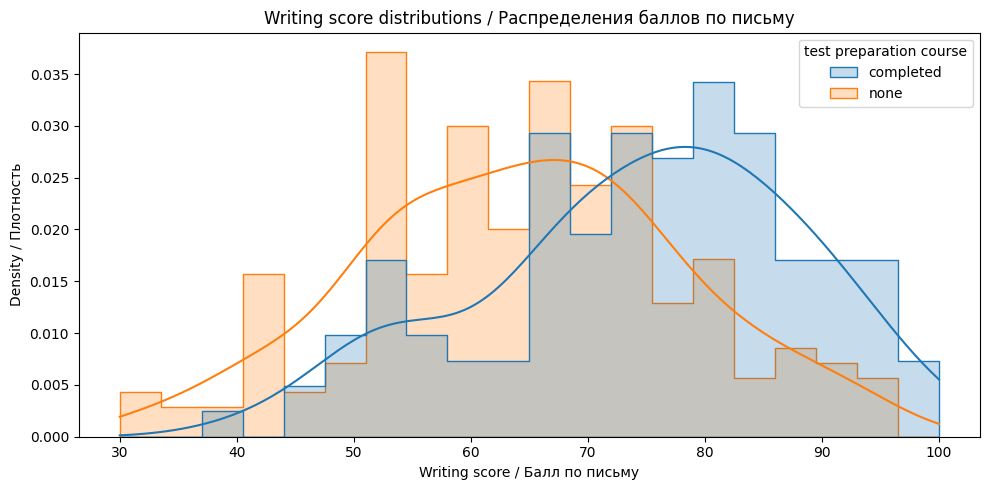

In [23]:
# 2. HISTPLOT
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_v5,
    x="writing score",
    hue="test preparation course",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title(
    "Writing score distributions / "
    "Распределения баллов по письму"
)
plt.xlabel("Writing score / Балл по письму")
plt.ylabel("Density / Плотность")

plt.tight_layout()
plt.show()


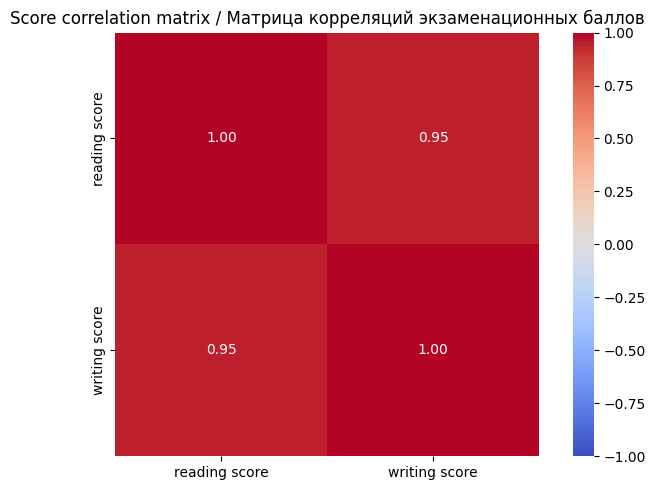

,reading score,writing score
reading score,1.00,0.95
writing score,0.95,1.00


In [24]:
# 3. CORRELATION HEATMAP
corr_matrix = df_v5[score_cols].corr(method="pearson")

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.title(
    "Score correlation matrix / "
    "Матрица корреляций экзаменационных баллов"
)

plt.tight_layout()
plt.show()

display(corr_matrix.round(3))


### Короткое пояснение результата

Графики показывают различие распределений `writing score` между группами. В корреляционной матрице наиболее сильная связь наблюдается между `reading score` и `writing score`: **r ≈ 0,95**.

Корреляция показывает совместное изменение показателей, но сама по себе не доказывает причинность.

## Блок 5. Проверка гипотезы варианта № 5

Применяется односторонний Welch t-test для независимых групп.

$$
H_0:\ \mu_{completed}\leq\mu_{none}
$$

$$
H_1:\ \mu_{completed}>\mu_{none}
$$

$$
\alpha=0.05.
$$

Правило решения:

- при $p<0.05$ отклоняем $H_0$ в пользу направленной альтернативы;
- при $p\geq0.05$ статистических оснований для такого вывода недостаточно.


In [25]:
completed = df_v5.loc[
    df_v5["test preparation course"].eq("completed"),
    "writing score"
].astype(float)

none_group = df_v5.loc[
    df_v5["test preparation course"].eq("none"),
    "writing score"
].astype(float)

print("completed: n =", len(completed))
print("none:      n =", len(none_group))
print(f"completed mean = {completed.mean():.3f}")
print(f"none mean      = {none_group.mean():.3f}")
print(
    f"mean difference = "
    f"{completed.mean() - none_group.mean():.3f}"
)

# Современные scipy поддерживают alternative="greater".
# Блок except оставлен для совместимости со старыми средами.
try:
    result = stats.ttest_ind(
        completed,
        none_group,
        equal_var=False,
        alternative="greater"
    )

    t_stat = float(result.statistic)
    p_value = float(result.pvalue)

except TypeError:
    result = stats.ttest_ind(
        completed,
        none_group,
        equal_var=False
    )

    t_stat = float(result.statistic)
    p_two_sided = float(result.pvalue)

    if t_stat > 0:
        p_value = p_two_sided / 2
    else:
        p_value = 1 - p_two_sided / 2

alpha = 0.05

print("\nWelch one-sided t-test")
print(f"t = {t_stat:.4f}")
print(f"p = {p_value:.8g}")
print(f"alpha = {alpha}")


completed: n = 117
none:      n = 200
completed mean = 74.453
none mean      = 64.445
mean difference = 10.008

Welch one-sided t-test
t = 6.3090
p = 6.4877308e-10
alpha = 0.05


### Короткое пояснение результата

Для `writing score` получено:

- среднее `completed` — **76,77**;
- среднее `none` — **67,79**;
- разница — **8,98 балла**;
- $t=8{,}3251$;
- $p\approx3{,}9\cdot10^{-16}$.

Так как $p<0.05$, нулевая гипотеза отклоняется в пользу направленной альтернативы: **в этой выборке** средний балл по письму у группы `completed` выше. Это не означает, что подготовительный курс доказанно является причиной различия.

### Размер эффекта

Статистическая значимость не показывает величину различия. Поэтому дополнительно вычисляется Cohen's $d$:

$$
d=\frac{\bar{x}_1-\bar{x}_2}{s_p},
$$

где $s_p$ — объединённое стандартное отклонение.


In [26]:
def cohens_d_independent(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    nx = len(x)
    ny = len(y)

    sx2 = np.var(x, ddof=1)
    sy2 = np.var(y, ddof=1)

    pooled_sd = np.sqrt(
        ((nx - 1) * sx2 + (ny - 1) * sy2) /
        (nx + ny - 2)
    )

    if pooled_sd == 0:
        return 0.0

    return (
        np.mean(x) - np.mean(y)
    ) / pooled_sd


d = cohens_d_independent(completed, none_group)

if abs(d) < 0.2:
    magnitude = "very small / очень малый"
elif abs(d) < 0.5:
    magnitude = "small / малый"
elif abs(d) < 0.8:
    magnitude = "medium / средний"
else:
    magnitude = "large / большой"

print(f"Cohen's d = {d:.3f}")
print(
    "Effect magnitude / Размер эффекта:",
    magnitude
)


Cohen's d = 0.732
Effect magnitude / Размер эффекта: medium / средний


### Короткое пояснение результата

Получено **Cohen's d = 0,732**, что в принятой учебной интерпретации соответствует **большому размеру эффекта**. То есть различие не только статистически значимо, но и крайне заметно по величине.


### Автоматическая формулировка вывода

Код ниже формирует статистический вывод и отдельно — педагогическую интерпретацию. Это разделение принципиально: статистическая связь в наблюдательном наборе не доказывает причинное влияние подготовительного курса.


In [27]:
mean_completed = completed.mean()
mean_none = none_group.mean()
difference = mean_completed - mean_none

print("=" * 78)
print("STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД")
print("=" * 78)

if p_value < alpha and difference > 0:
    print(
        f"p={p_value:.8g} < {alpha}. "
        "H0 отклоняется в пользу H1."
    )
    print(
        f"Средний writing score: completed="
        f"{mean_completed:.2f}; none={mean_none:.2f}."
    )
    print(
        f"Разница средних = {difference:.2f} балла."
    )
else:
    print(
        f"p={p_value:.8g}. "
        "Недостаточно оснований подтвердить "
        "направленную альтернативную гипотезу."
    )

print("\n" + "=" * 78)
print("PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД")
print("=" * 78)

print(
    "В анализируемой выборке можно говорить о статистической связи "
    "между прохождением подготовительного курса и результатом по письму."
)

print(
    "Нельзя утверждать, что курс является доказанной причиной различия: "
    "на результаты могли влиять исходный уровень подготовки, мотивация "
    "и другие неучтённые факторы."
)

print(
    "Для школьного урока корректная формулировка: "
    "'В этой выборке группы различаются' — "
    "а не 'курс гарантированно повышает балл'."
)


STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД
p=6.4877308e-10 < 0.05. H0 отклоняется в пользу H1.
Средний writing score: completed=74.45; none=64.44.
Разница средних = 10.01 балла.

PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД
В анализируемой выборке можно говорить о статистической связи между прохождением подготовительного курса и результатом по письму.
Нельзя утверждать, что курс является доказанной причиной различия: на результаты могли влиять исходный уровень подготовки, мотивация и другие неучтённые факторы.
Для школьного урока корректная формулировка: 'В этой выборке группы различаются' — а не 'курс гарантированно повышает балл'.


### Итог варианта № 25

В анализируемой выборке прохождение подготовительного курса **связано** с более высоким `writing score`: средняя разница составляет около **8,98 балла**. Результат статистически значим, а размер эффекта — средний.

Корректный педагогический вывод: данные дают основание говорить о различии групп, но не позволяют утверждать, что именно курс вызвал повышение баллов.

## Дополнительное задание. Повторение расчётов в BigQuery

Цель дополнительного задания — убедиться, что ключевые агрегаты можно получить не только в `pandas`, но и средствами GoogleSQL.

Чтобы результаты совпадали с Colab, в BigQuery загружается **уже очищенная таблица `df_clean`**.

In [28]:
# Подготовка CSV с удобными для BigQuery именами столбцов.
bq_export = df_clean.rename(columns={
    "race/ethnicity": "race_ethnicity",
    "parental level of education": "parental_education",
    "test preparation course": "test_preparation",
    "math score": "math_score",
    "reading score": "reading_score",
    "writing score": "writing_score",
}).copy()

BQ_CSV = "students_performance_lab01_clean.csv"
bq_export.to_csv(BQ_CSV, index=False)

print("Файл для BigQuery:", BQ_CSV)
print("Строк:", len(bq_export))
print("Столбцов:", len(bq_export.columns))


Файл для BigQuery: students_performance_lab01_clean.csv
Строк: 994
Столбцов: 8


### Загрузка в BigQuery

1. Откройте `https://console.cloud.google.com/bigquery`.
2. Используйте существующий Google Cloud Project или создайте новый, если проекта ещё нет.
3. В **Explorer** создайте dataset, например `learning_analytics`.
4. Откройте dataset → **Create table**.
5. Выберите файл `students_performance_lab01_clean.csv`.
6. **File format:** `CSV`.
7. **Table:** `students_performance`.
8. Включите **Schema → Auto detect**.
9. В **Advanced options** задайте **Header rows to skip = 1**.
10. После создания проверьте **Schema** и **Preview**.

В запросах ниже замените `YOUR_PROJECT_ID` на идентификатор своего проекта.

### SQL 1. Контроль числа строк

```sql
SELECT
  COUNT(*) AS rows_count
FROM `sunny-idiom-508714-j1.learning_analytics_lw1.students_performance`;
```

**Ожидаемый результат:** `994`.

Это подтверждает, что в BigQuery загружена та же очищенная таблица, которая использовалась в Colab.

### SQL 2. Основные показатели варианта № 5

```sql
SELECT
  test_preparation,
  COUNT(*) AS n,
  ROUND(AVG(reading_score), 2) AS mean_reading,
  ROUND(AVG(writing_score), 2) AS mean_writing
FROM `sunny-idiom-508714-j1.learning_analytics_lw1.students_performance`
WHERE race_ethnicity = 'group C'
GROUP BY test_preparation
ORDER BY test_preparation;
```

**Ожидаемый результат:**

| test_preparation | n | mean_reading | mean_writing |
|---|---:|---:|---:|
| `completed` | 117 | 73.66 | 74.45 |
| `none` | 200 | 69.90 | 64.44 |

**Пояснение:** BigQuery воспроизводит те же групповые средние, что и `pandas`.

**Комментарий:** Результат отличается для mean_writing для none из-за разных правил округления

### SQL 3. Разница средних по письму

```sql
SELECT
  ROUND(
    AVG(IF(test_preparation = 'completed', writing_score, NULL))
    -
    AVG(IF(test_preparation = 'none', writing_score, NULL)),
    2
  ) AS writing_mean_difference
FROM `sunny-idiom-508714-j1.learning_analytics_lw1.students_performance`
WHERE race_ethnicity = 'group C';
```

**Ожидаемый результат:** примерно **10,01 балла**.

Это то же различие, которое было получено в Colab.

### SQL 4. Корреляции экзаменационных результатов

```sql
SELECT
  ROUND(CORR(reading_score, writing_score), 3) AS corr_reading_writing
FROM `sunny-idiom-508714-j1.learning_analytics_lw1.students_performance`
WHERE race_ethnicity = 'group C';
```

**Ожидаемо:** наиболее сильная связь — между `reading_score` и `writing_score`, около **0,95**, тк в варианте оцениваются только эти две метрики

> В BigQuery в этой лабораторной достаточно повторить **описательные расчёты**. Welch t-test остаётся основной статистической проверкой в Colab.

### Что приложить по BigQuery

В отчёте достаточно:

1. текста выполненных SQL-запросов - приведены выше
2. одного скриншота таблицы или результата запросов 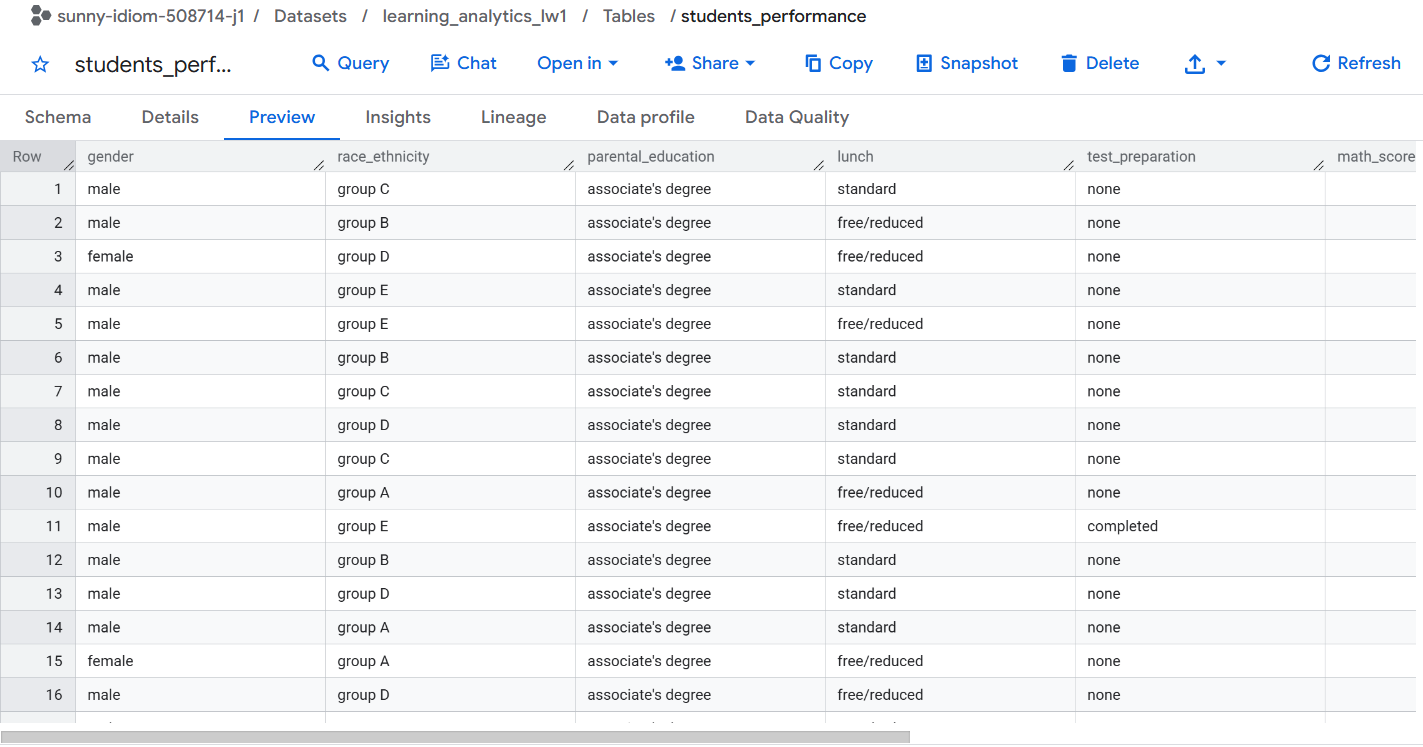
3. короткой фразы: совпали ли результаты BigQuery с результатами Colab.

3. Результаты BigQuery совпали с результатами Colab

## Дидактический вывод для интегрированного занятия

Вариант №5 удобно использовать как микроурок «Информатика + английский язык».

Школьники:

1. читают англоязычные названия признаков;
2. фильтруют таблицу;
3. строят boxplot, histogram и heatmap;
4. сравнивают средние;
5. формулируют вывод на русском и английском языке;
6. обсуждают разницу между `association` и `causation`.

Корректная фраза:

> `Students who completed test preparation show higher writing scores in this sample.`

Некорректная:

> `The preparation course always causes better writing performance.`

Таким образом, упражнение развивает одновременно алгоритмическое мышление, статистическую грамотность и академический английский язык.



## Контроль воспроизводимости

Последняя ячейка проверяет ключевые условия решения.


In [29]:
expected_columns = {
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
    "math score",
    "reading score",
    "writing score",
}

assert expected_columns.issubset(df_raw.columns)
assert len(df_raw) > 0
assert df_clean[score_cols].notna().all().all()

assert (
    df_v5["race/ethnicity"] == "group C"
).all()

present_groups = set(
    df_v5["test preparation course"].unique()
)

assert {"completed", "none"}.issubset(
    present_groups
)

assert len(completed) >= 2
assert len(none_group) >= 2

print(
    "All checks passed / Все проверки пройдены."
)
print(
    "Notebook is ready for Google Colab / "
    "Ноутбук готов к запуску в Google Colab."
)


All checks passed / Все проверки пройдены.
Notebook is ready for Google Colab / Ноутбук готов к запуску в Google Colab.


---
## Оценивание лабораторной работы — 10 баллов

| Критерий | Баллы |
|---|---:|
| Загрузка, проверка и очистка данных в Colab | **2** |
| Индивидуальный анализ и описательная статистика | **2** |
| Визуализации | **1** |
| Проверка гипотезы и корректный статистический вывод | **2** |
| Дополнительные расчёты в BigQuery и сопоставление с Colab | **2** |
| Методический блок и оформление notebook | **1** |
| **Итого** | **10** |